<a href="https://colab.research.google.com/github/josslaurent/Machine_learning_Assignment_3/blob/main/Machine_learning_Assignment_3_Joss_LAURENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Assignment 3 ( JOSS LAURENT ) Neural networks on Fashion-MNIST
Goal: build and compare simple neural networks that classify 28×28 clothing images into 10 categories.

## Data preparation

In [11]:
import tensorflow as tf
# Load Fashion-MNIST
(X_train, y_train), (X_test, y_test) = (
tf.keras.datasets.fashion_mnist.load_data()
)
# Normalize pixel values to [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
# Flatten 28 x 28 images into 784 features
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)
# Next step:
# Split the training data into training and validation subsets.
# Keep the test data separate for final evaluation.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)
print(X_train.shape, X_val.shape, X_test.shape)

(48000, 784) (12000, 784) (10000, 784)


The pixel values are divided by 255 so they are between 0 and 1, which helps training. Each 28×28 image is flattened into 784 input features. The training data is split into 48,000 training images and 12,000 validation images. The validation set is used to compare the models, and the 10,000 test images are kept for the final evaluation only.

## Part A : Task 1: Baseline model
784 inputs → 32 hidden neurons (ReLU) → 10 output neurons (softmax). Optimizer: Adam, 10 epochs, batch size 64.

In [13]:
model_baseline = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_baseline = model_baseline.fit(
    X_train, y_train,
    epochs=10, batch_size=64,
    validation_data=(X_val, y_val)
)

print("Train accuracy:", history_baseline.history["accuracy"][-1])
print("Validation accuracy:", history_baseline.history["val_accuracy"][-1])

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7850 - loss: 0.6306 - val_accuracy: 0.8484 - val_loss: 0.4481
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8492 - loss: 0.4294 - val_accuracy: 0.8589 - val_loss: 0.4110
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8599 - loss: 0.3931 - val_accuracy: 0.8631 - val_loss: 0.3845
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8656 - loss: 0.3732 - val_accuracy: 0.8648 - val_loss: 0.3819
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8729 - loss: 0.3543 - val_accuracy: 0.8709 - val_loss: 0.3606
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8755 - loss: 0.3436 - val_accuracy: 0.8737 - val_loss: 0.3552
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8797 - loss: 0.3321 - val_accuracy: 0.8813 - val_loss: 0.3433
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8833 - loss: 0.3226 - val_accuracy: 0.

Result: training accuracy 0.886, validation accuracy 0.874. The two values are close, so the model does not overfit much.

## Part A : Task 2: Experiments
In each experiment, only one setting is changed compared to the baseline, so we can see the effect of that setting alone.

In [14]:
model_exp1 = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_exp1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_exp1 = model_exp1.fit(
    X_train, y_train,
    epochs=10, batch_size=64,
    validation_data=(X_val, y_val)
)

print("Train accuracy:", history_exp1.history["accuracy"][-1])
print("Validation accuracy:", history_exp1.history["val_accuracy"][-1])

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8055 - loss: 0.5726 - val_accuracy: 0.8398 - val_loss: 0.4543
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8491 - loss: 0.4284 - val_accuracy: 0.8633 - val_loss: 0.3931
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8633 - loss: 0.3860 - val_accuracy: 0.8524 - val_loss: 0.4277
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8680 - loss: 0.3663 - val_accuracy: 0.8754 - val_loss: 0.3596
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8768 - loss: 0.3435 - val_accuracy: 0.8753 - val_loss: 0.3579
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8805 - loss: 0.3303 - val_accuracy: 0.8777 - val_loss: 0.3555
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8853 - loss: 0.3174 - val_accuracy: 0.8830 - val_loss: 0.3380
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8884 - loss: 0.3075 - val_accuracy: 0.

In [15]:
model_exp2 = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_exp2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_exp2 = model_exp2.fit(
    X_train, y_train,
    epochs=10, batch_size=64,
    validation_data=(X_val, y_val)
)

print("Train accuracy:", history_exp2.history["accuracy"][-1])
print("Validation accuracy:", history_exp2.history["val_accuracy"][-1])

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7972 - loss: 0.6093 - val_accuracy: 0.8432 - val_loss: 0.4425
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8503 - loss: 0.4259 - val_accuracy: 0.8550 - val_loss: 0.4078
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8622 - loss: 0.3890 - val_accuracy: 0.8669 - val_loss: 0.3754
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8699 - loss: 0.3657 - val_accuracy: 0.8748 - val_loss: 0.3587
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8759 - loss: 0.3495 - val_accuracy: 0.8762 - val_loss: 0.3569
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8776 - loss: 0.3386 - val_accuracy: 0.8767 - val_loss: 0.3502
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8841 - loss: 0.3248 - val_accuracy: 0.8787 - val_loss: 0.3404
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8868 - loss: 0.3161 - val_accuracy: 0.

In [16]:
model_exp3 = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model_exp3.compile(
    optimizer="sgd",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_exp3 = model_exp3.fit(
    X_train, y_train,
    epochs=10, batch_size=64,
    validation_data=(X_val, y_val)
)

print("Train accuracy:", history_exp3.history["accuracy"][-1])
print("Validation accuracy:", history_exp3.history["val_accuracy"][-1])

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6699 - loss: 1.0582 - val_accuracy: 0.7682 - val_loss: 0.7155
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7848 - loss: 0.6554 - val_accuracy: 0.8083 - val_loss: 0.5883
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8099 - loss: 0.5742 - val_accuracy: 0.8238 - val_loss: 0.5349
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8191 - loss: 0.5341 - val_accuracy: 0.8301 - val_loss: 0.5057
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8261 - loss: 0.5092 - val_accuracy: 0.8331 - val_loss: 0.4861
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8329 - loss: 0.4914 - val_accuracy: 0.8351 - val_loss: 0.4744
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8344 - loss: 0.4784 - val_accuracy: 0.8417 - val_loss: 0.4577
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8404 - loss: 0.4669 - val_accuracy: 0.

Summary of the experiments:

-64 neurons: best result (validation 0.887). More neurons give the network more capacity to learn patterns.

-tanh: same validation accuracy as the baseline (0.874). The activation function made little difference here.

-SGD: lowest result (validation 0.853). With default settings, SGD learns more slowly than Adam, and its accuracy was still increasing at epoch 10.

## Part A : Task 3: Results and test evaluation

In [17]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Baseline", "Experiment 1", "Experiment 2", "Experiment 3"],
    "Hidden neurons": [32, 64, 32, 32],
    "Activation": ["ReLU", "ReLU", "tanh", "ReLU"],
    "Optimizer": ["Adam", "Adam", "Adam", "SGD"],
    "Train accuracy": [
        history_baseline.history["accuracy"][-1],
        history_exp1.history["accuracy"][-1],
        history_exp2.history["accuracy"][-1],
        history_exp3.history["accuracy"][-1]
    ],
    "Validation accuracy": [
        history_baseline.history["val_accuracy"][-1],
        history_exp1.history["val_accuracy"][-1],
        history_exp2.history["val_accuracy"][-1],
        history_exp3.history["val_accuracy"][-1]
    ]
})

results

,Model,Hidden neurons,Activation,Optimizer,Train accuracy,Validation accuracy
0,Baseline,32,ReLU,Adam,0.887937,0.876833
1,Experiment 1,64,ReLU,Adam,0.895646,0.882000
2,Experiment 2,32,tanh,Adam,0.889771,0.882250
3,Experiment 3,32,ReLU,SGD,0.843875,0.841333


In [18]:
best_model = model_exp1

test_loss, test_accuracy = best_model.evaluate(X_test, y_test)
print("Test accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8691 - loss: 0.3663
Test accuracy: 0.8690999746322632


Experiment 1 (64 neurons) has the highest validation accuracy, so it is selected. The test set was not used to choose the model.

Test accuracy of the selected model: 0.876, close to its validation accuracy (0.887), so the model generalises well to new images.

## Part B : Questions

Q1. Architecture and parameters

-Hidden layer: 784 × 32 = 25,088 weights + 32 biases = 25,120

-Output layer: 32 × 10 = 320 weights + 10 biases = 330

-Total: 25,450 trainable parameters (25,408 weights and 42 biases)


A parameter is a value the model learns during training (weights and biases). A hyperparameter is a setting we choose before training, such as the number of neurons, the activation function, the optimizer, the number of epochs or the batch size.

Q2. Activation and loss

ReLU is used in the hidden layer because it is simple (it outputs 0 for negative values and the value itself otherwise) and adds non-linearity, so the network can learn complex patterns. It also trains quickly. Softmax is used in the output layer because it turns the 10 outputs into probabilities that add up to 1, one for each clothing category; the predicted class is the one with the highest probability. Sparse categorical cross-entropy is used because this is a multiclass problem with exactly one correct class per image, and the labels are stored as integers (0–9). The loss is low when the model gives a high probability to the correct class and high when it gives a low probability.

Q3. Training and Keras functions

-`model.compile()` sets the optimizer, the loss function and the metric (accuracy).

-`model.fit()` trains the model on the training data for a number of epochs, in batches.

-`model.evaluate()` calculates the loss and accuracy on data, without training.

-`model.predict()` returns the 10 probabilities for each new image.


During training, the model makes a prediction (forward pass) and calculates the loss. Backpropagation then calculates how much each weight and bias contributed to the error (the gradients), going backward from the output layer to the hidden layer. The **optimizer** (Adam or SGD) uses these gradients to update the weights and biases so the loss decreases. This is repeated for every batch and every epoch.

Q4. Interpreting the experiments

Experiment 1 (64 neurons) achieved the highest validation accuracy (0.887, compared to 0.874 for the baseline). The changes did not always improve accuracy: tanh gave the same validation accuracy as ReLU (0.874), and SGD made it worse (0.853) because it learns more slowly than Adam with default settings, so 10 epochs were not enough. More neurons helped, but the gain was small (about 1 percentage point). Results can also vary a little between runs because of random weight initialisation.

## Part C : Confusion matrix

The model most often confuses Shirt and T-shirt/top: 144 shirts were predicted as T-shirt/top, and 94 T-shirts were predicted as shirts. These two classes have a very similar shape in 28×28 grayscale images.

The overall test accuracy (87.6%) is a single number for all classes. The confusion matrix shows the results for each class: some classes are almost always correct (Trouser 969/1000, Bag 962/1000), while Shirt is correct only 641/1000 times. It also shows which classes are mixed up with each other, which accuracy alone cannot show.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


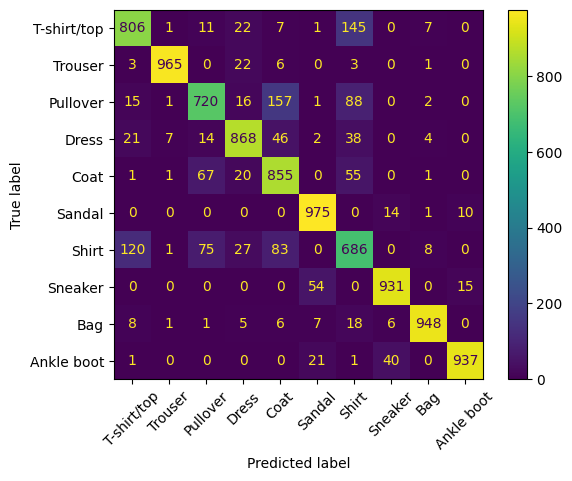

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

probabilities = best_model.predict(X_test)
y_pred = np.argmax(probabilities, axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(xticks_rotation=45)
plt.show()

## Declaration

This assignment was completed by me (Joss Laurent), using the course material (lecture slides and the Keras example notebook). I used an AI assistant (Claude) as support: to help write and structure the code, create the confusion matrix plot, and draft and improve the wording of the explanations and answers. I ran all the experiments myself, checked the results, and made sure I understand the code and the answers so I can explain them during the oral examination.